# PerfectPetClub Customer Churn Dashboard
Reads `customer_churn.parquet` (made by `ETL.ipynb`) and builds the KPIs, charts and the combined dashboard image.

## 1. Load the data

In [7]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def find_project_dir():
    """Return (project folder, data folder), whichever of Data/data exists."""
    here = Path.cwd().resolve()
    for base in (here, here.parent):
        for name in ("Data", "data"):
            if (base / name).is_dir():
                return base, base / name
    raise FileNotFoundError("Data folder not found. Open the notebook from the project or notebooks folder.")

PROJECT_DIR, DATA_DIR = find_project_dir()
DATA_PATH = DATA_DIR / "customer_churn.parquet"
DASHBOARD_PNG = PROJECT_DIR / "customer_churn_dashboard.png"

df = pd.read_parquet(DATA_PATH)
print("Loaded", DATA_PATH, df.shape)
display(df.head())

Loaded C:\Users\Admin\P3G7-PerfectPetClub-Customer-Churn\Data\customer_churn.parquet (221, 22)


,subscription_id,start_date,end_date,subscription_type_id,id,name_type,delivery_service,churn,customer_id,total_orders,...,total_items_purchased,total_crm_interactions,complaint_count,query_count,total_logins,unique_sessions,reported_income,nps_recommend,satisfaction_score,online_comparison_freq
0,1,2026-01-01 00:00:00.000,2026-01-31 00:00:00.000,3,3,SuperSaver,Economy72,1,1,20,...,46,3.0,2.0,1.0,48,48,26k-30k,8,6,5
1,2,2026-01-01 00:00:00.000,2026-11-27 00:00:00.000,3,3,SuperSaver,Economy72,0,2,253,...,748,45.0,21.0,24.0,1085,1085,34k-38k,5,8,9
2,3,2026-01-01 00:00:00.000,2026-11-27 00:00:00.000,1,1,Premium,SignedFor24,0,3,304,...,824,167.0,90.0,77.0,624,624,26k-30k,9,5,5
3,4,2026-01-01 00:00:00.000,2026-11-27 00:00:00.000,1,1,Premium,SignedFor24,0,4,1055,...,7362,281.0,132.0,149.0,1540,1540,198k-200k+,9,3,5
4,5,2026-01-01 00:00:00.000,2026-05-01 00:00:00.000,3,3,SuperSaver,Economy72,1,5,44,...,116,5.0,1.0,4.0,388,388,42k-46k,0,8,10


## 2. KPIs

In [8]:
total_customers = len(df)
churned_customers = int(df["churn"].sum())
retained_customers = total_customers - churned_customers
churn_rate = churned_customers / total_customers * 100

kpi_labels = ["Total Customers", "Churned Customers", "Retained Customers", "Churn Rate"]
kpi_values = [total_customers, churned_customers, retained_customers, f"{churn_rate:.2f}%"]

display(pd.DataFrame({"Metric": kpi_labels, "Value": kpi_values}))

,Metric,Value
0,Total Customers,221
1,Churned Customers,86
2,Retained Customers,135
3,Churn Rate,38.91%


## 3. Numbers behind the charts

In [9]:
STATUS = {0: "Retained", 1: "Churned"}

churn_counts = df["churn"].value_counts().sort_index().rename(index=STATUS)

subscription_churn = (
    df.groupby("name_type")["churn"].mean().mul(100).sort_values(ascending=False)
)
avg_complaints = df.groupby("churn")["complaint_count"].mean().rename(index=STATUS)
avg_logins = df.groupby("churn")["total_logins"].mean().rename(index=STATUS)
avg_satisfaction = df.groupby("churn")["satisfaction_score"].mean().rename(index=STATUS)

summary = pd.concat(
    [avg_complaints, avg_logins, avg_satisfaction], axis=1,
    keys=["Avg complaints", "Avg logins", "Avg satisfaction"],
).round(2)

display(subscription_churn.round(2).to_frame("Churn rate (%)"))
display(summary)

,Churn rate (%)
name_type,
SuperSaver,42.27
Premium,40.43
Basic,33.77


,Avg complaints,Avg logins,Avg satisfaction
churn,,,
Retained,20.68,350.75,4.62
Churned,12.15,231.37,4.98


## 4. Charts
Every chart is described once in `PANELS` and drawn by `draw_panel`, so the single charts and the combined dashboard use the same code.

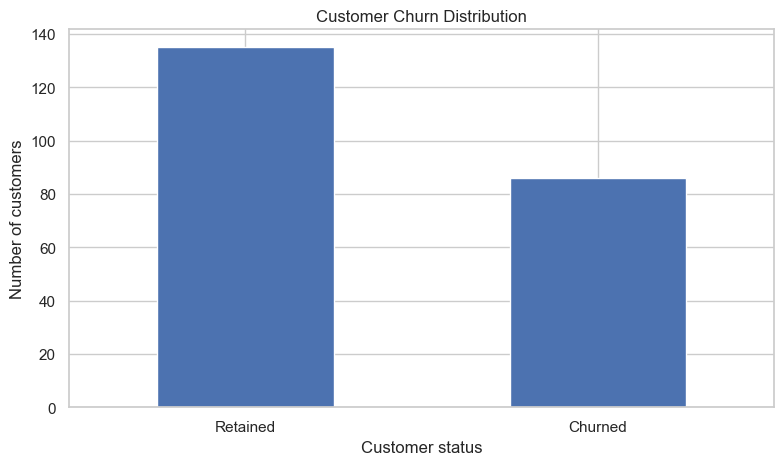

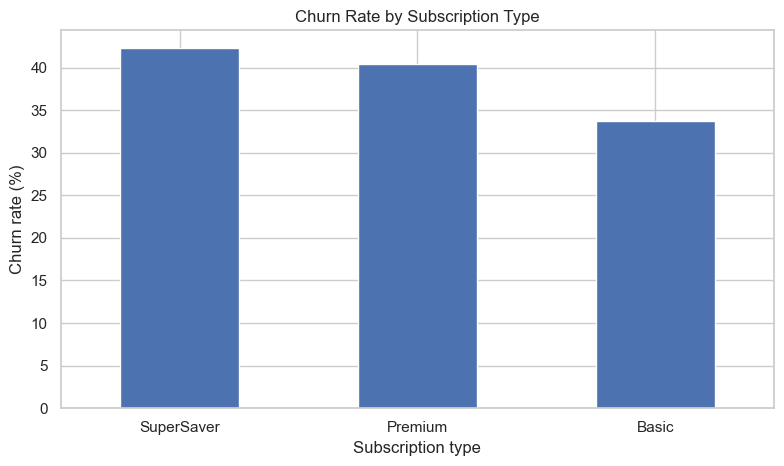

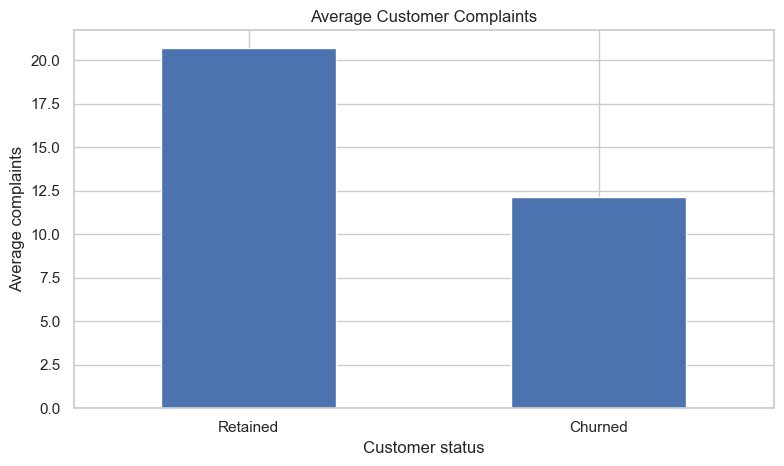

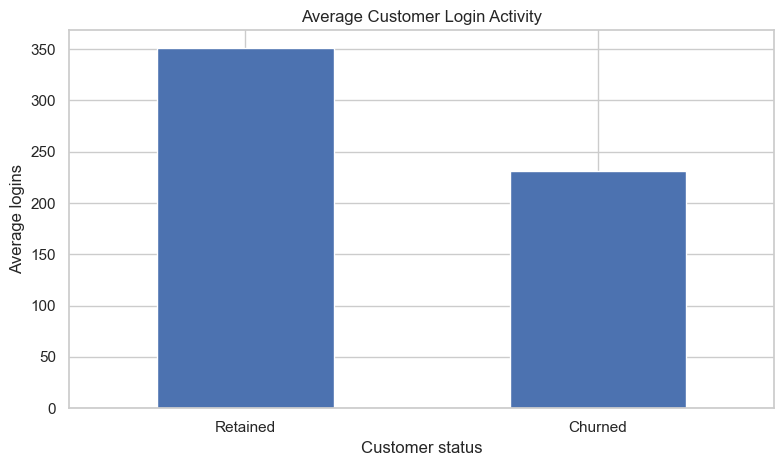

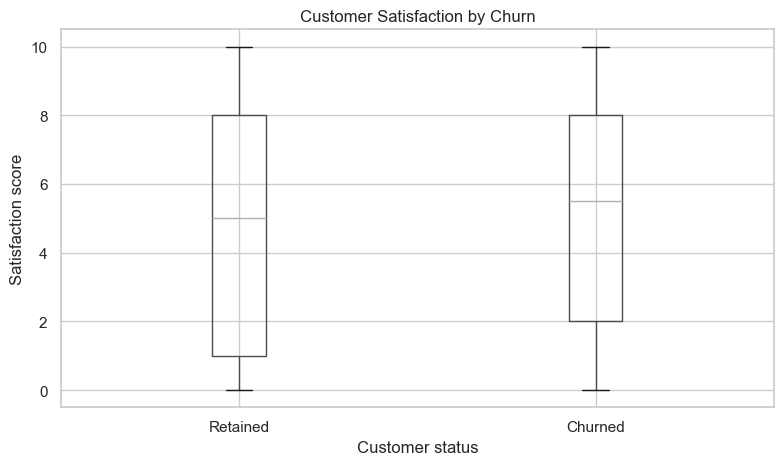

In [10]:
PANELS = [
    dict(kind="bar", data=churn_counts, title="Customer Churn Distribution",
         xlabel="Customer status", ylabel="Number of customers"),
    dict(kind="bar", data=subscription_churn, title="Churn Rate by Subscription Type",
         xlabel="Subscription type", ylabel="Churn rate (%)"),
    dict(kind="bar", data=avg_complaints, title="Average Customer Complaints",
         xlabel="Customer status", ylabel="Average complaints"),
    dict(kind="bar", data=avg_logins, title="Average Customer Login Activity",
         xlabel="Customer status", ylabel="Average logins"),
    dict(kind="box", data=None, title="Customer Satisfaction by Churn",
         xlabel="Customer status", ylabel="Satisfaction score"),
]


def draw_panel(ax, panel):
    if panel["kind"] == "bar":
        panel["data"].plot(kind="bar", ax=ax)
        ax.tick_params(axis="x", rotation=0)
    else:
        df.boxplot(column="satisfaction_score", by="churn", ax=ax)
        ax.set_xticklabels([STATUS[v] for v in sorted(df["churn"].unique())])
    ax.set_title(panel["title"])
    ax.set_xlabel(panel["xlabel"])
    ax.set_ylabel(panel["ylabel"])


for panel in PANELS:
    fig, ax = plt.subplots(figsize=(8, 5))
    draw_panel(ax, panel)
    fig.suptitle("")  # boxplot adds its own title
    fig.tight_layout()
    plt.show()

## 5. Combined dashboard

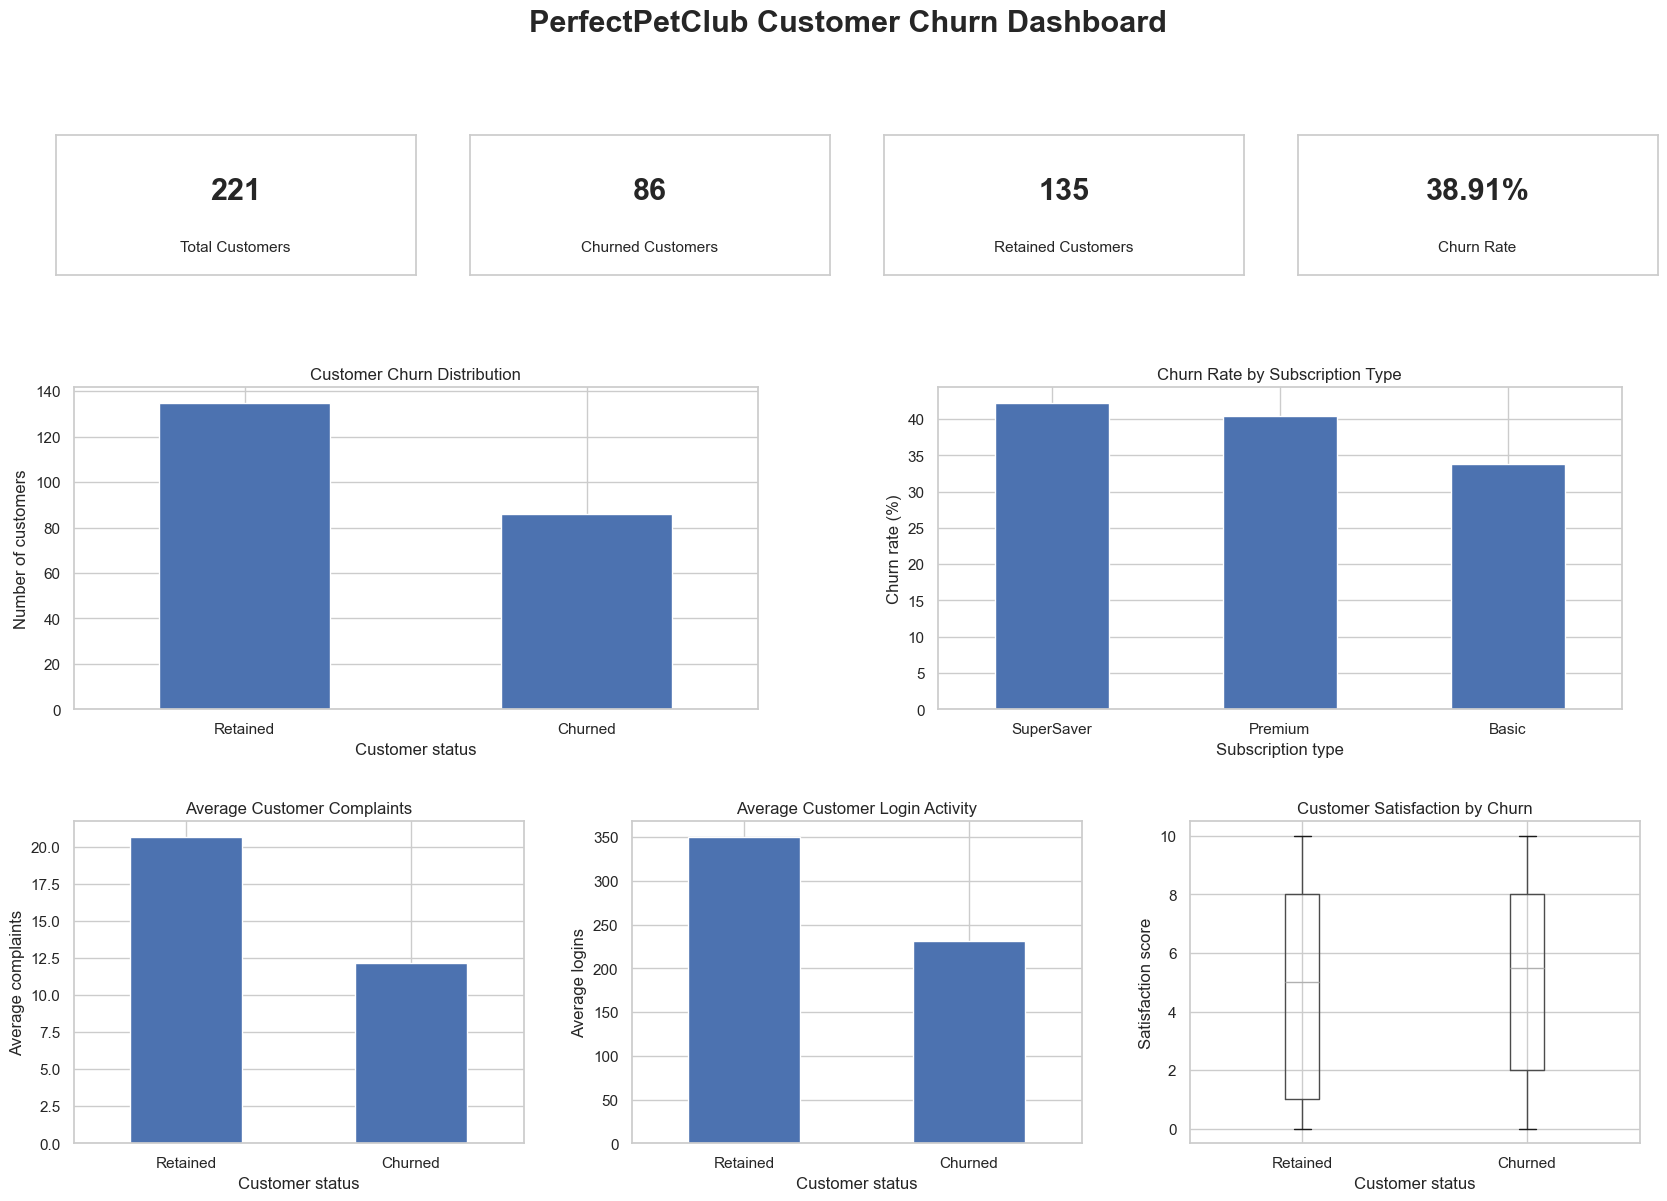

Saved C:\Users\Admin\P3G7-PerfectPetClub-Customer-Churn\customer_churn_dashboard.png


In [5]:
TITLE = "PerfectPetClub Customer Churn Dashboard"

# [left, bottom, width, height] as fractions of the figure
KPI_BOXES = [[0.06, 0.79, 0.20, 0.10], [0.29, 0.79, 0.20, 0.10],
             [0.52, 0.79, 0.20, 0.10], [0.75, 0.79, 0.20, 0.10]]
CHART_BOXES = [[0.07, 0.48, 0.38, 0.23], [0.55, 0.48, 0.38, 0.23],
               [0.07, 0.17, 0.25, 0.23], [0.38, 0.17, 0.25, 0.23],
               [0.69, 0.17, 0.25, 0.23]]

fig = plt.figure(figsize=(18, 14))

for box, label, value in zip(KPI_BOXES, kpi_labels, kpi_values):
    ax = fig.add_axes(box)
    ax.text(0.5, 0.60, str(value), ha="center", va="center", fontsize=22, fontweight="bold")
    ax.text(0.5, 0.20, label, ha="center", va="center", fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])

for box, panel in zip(CHART_BOXES, PANELS):
    draw_panel(fig.add_axes(box), panel)

# set the title last, because the boxplot overwrites it
fig.suptitle(TITLE, fontsize=22, fontweight="bold", y=0.98)

fig.savefig(DASHBOARD_PNG, dpi=300, bbox_inches="tight")
plt.show()
print("Saved", DASHBOARD_PNG)

## 6. Final checks

In [6]:
checks = {
    "Parquet file exists": DATA_PATH.exists(),
    "Dashboard image exists": DASHBOARD_PNG.exists(),
    "Customer IDs unique": df["customer_id"].is_unique,
    "Customer IDs not missing": df["customer_id"].notna().all(),
    "Churn values are 0/1": set(df["churn"].unique()) <= {0, 1},
    "Dataset has rows": len(df) > 0,
}

for name, ok in checks.items():
    print(f"{name}: {'PASS' if ok else 'FAIL'}")

assert all(checks.values()), "One or more checks failed"

Parquet file exists: PASS
Dashboard image exists: PASS
Customer IDs unique: PASS
Customer IDs not missing: PASS
Churn values are 0/1: PASS
Dataset has rows: PASS
